In [20]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

Device : cuda
GPU : Tesla T4


In [21]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))   # moyenne et écart-type de MNIST
])

train_ds = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=1000)

print(len(train_ds), len(test_ds))   # 60000 10000

60000 10000


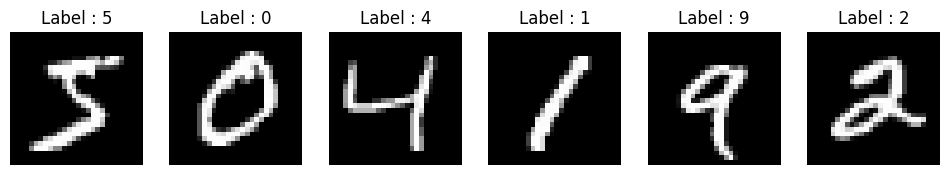

In [22]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for ax, i in zip(axes, range(6)):
    img, label = train_ds[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"Label : {label}")
    ax.axis("off")
plt.show()

In [23]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)
        self.drop  = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

model = CNN().to(device)
print(model)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (drop): Dropout(p=0.5, inplace=False)
)
Paramètres : 421642


In [24]:
def train_model(model, loader, epochs, optimizer, criterion):
    model.train()
    losses = []
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.time()

    for ep in range(epochs):
        running = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)      # données envoyées sur le GPU
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item()
        losses.append(running / len(loader))
        print(f"Epoch {ep+1}/{epochs} - loss : {losses[-1]:.4f}")

    if device.type == "cuda": torch.cuda.synchronize()
    return losses, time.time() - start


def evaluate_model(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            preds += out.argmax(1).cpu().tolist()
            labels += y.tolist()
    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="macro")
    return acc, f1, labels, preds

In [25]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

cnn_losses, cnn_time = train_model(model, train_loader, epochs=10,
                                   optimizer=optimizer, criterion=criterion)

Epoch 1/10 - loss : 0.2087
Epoch 2/10 - loss : 0.0765
Epoch 3/10 - loss : 0.0603
Epoch 4/10 - loss : 0.0511
Epoch 5/10 - loss : 0.0424
Epoch 6/10 - loss : 0.0389
Epoch 7/10 - loss : 0.0339
Epoch 8/10 - loss : 0.0306
Epoch 9/10 - loss : 0.0292
Epoch 10/10 - loss : 0.0268


Accuracy : 0.9929 | F1 macro : 0.9928 | Temps : 142.2s


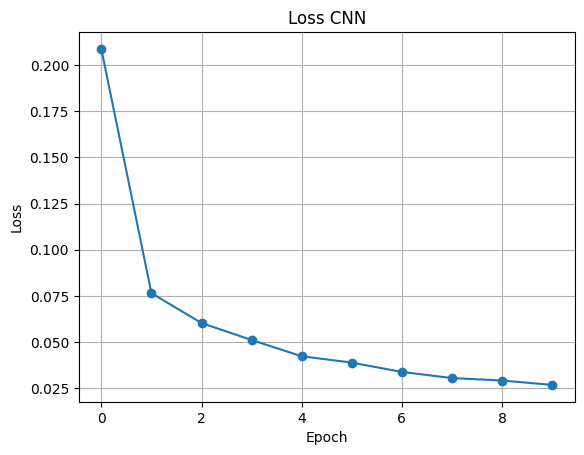

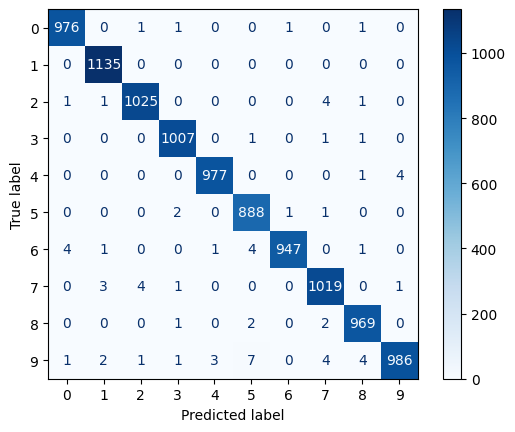

In [26]:
acc, f1, labels, preds = evaluate_model(model, test_loader)
print(f"Accuracy : {acc:.4f} | F1 macro : {f1:.4f} | Temps : {cnn_time:.1f}s")

# Courbe de loss
plt.plot(cnn_losses, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss CNN"); plt.grid()
plt.show()

# Matrice de confusion
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.show()

torch.save(model.state_dict(), "cnn.pth")

Le CNN construit from scratch atteint une accuracy de 99,29 % et un F1-score macro de 99,28 % sur le jeu de test MNIST, avec un temps d’entraînement de 142,2 s sur GPU pour environ 421 k paramètres. La loss chute rapidement lors des deux premières epochs (de 0,21 à 0,076), puis décroît lentement jusqu’à 0,027 sans oscillation ni signe de surapprentissage. La matrice de confusion montre une diagonale très dominante, avec seulement 71 erreurs sur 10 000 images, principalement entre des chiffres de forme proche (9/5, 7/2, 4/9), tandis que le chiffre 1 est parfaitement reconnu. Ce modèle léger et performant servira de référence pour la comparaison avec AlexNet et VGG16.

In [27]:
results = {}
results["CNN"] = {
    "acc": acc, "f1": f1, "loss": cnn_losses[-1], "time": cnn_time,
    "params": sum(p.numel() for p in model.parameters())
}

In [28]:
tf_pretrained = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_full = datasets.MNIST("./data", train=True,  download=True, transform=tf_pretrained)
test_full  = datasets.MNIST("./data", train=False, download=True, transform=tf_pretrained)

# Sous-ensembles pour gagner du temps
train_sub = Subset(train_full, range(10000))
test_sub  = Subset(test_full,  range(2000))

train_loader_pt = DataLoader(train_sub, batch_size=32, shuffle=True)
test_loader_pt  = DataLoader(test_sub,  batch_size=64)

In [32]:
def get_alexnet():
    m = models.alexnet(weights="DEFAULT")
    m.classifier[6] = nn.Linear(4096, 10)   # 1000 classes ImageNet → 10 chiffres
    return m.to(device)

def get_vgg16():
    m = models.vgg16(weights="DEFAULT")
    m.classifier[6] = nn.Linear(4096, 10)
    return m.to(device)

In [33]:
def freeze_features(m):
    for p in m.features.parameters():
        p.requires_grad = False

In [34]:
def run_experiment(name, build_fn, freeze, epochs=3, lr=1e-4):
    m = build_fn()
    if freeze:
        freeze_features(m)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=lr)
    losses, t = train_model(m, train_loader_pt, epochs, opt, nn.CrossEntropyLoss())
    acc, f1, labels, preds = evaluate_model(m, test_loader_pt)
    results[name] = {
        "acc": acc, "f1": f1, "loss": losses[-1], "time": t,
        "params": sum(p.numel() for p in m.parameters())
    }
    print(f"{name} → Acc {acc:.4f} | F1 {f1:.4f} | Temps {t:.0f}s")
    del m; torch.cuda.empty_cache()    # libère la mémoire GPU

In [35]:
run_experiment("AlexNet (gelé)",   get_alexnet, freeze=True)
run_experiment("AlexNet (complet)", get_alexnet, freeze=False)
run_experiment("VGG16 (gelé)",     get_vgg16,   freeze=True)
run_experiment("VGG16 (complet)",  get_vgg16,   freeze=False)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 233MB/s] 


Epoch 1/3 - loss : 0.2857
Epoch 2/3 - loss : 0.0808
Epoch 3/3 - loss : 0.0584
AlexNet (gelé) → Acc 0.9750 | F1 0.9751 | Temps 60s
Epoch 1/3 - loss : 0.1942
Epoch 2/3 - loss : 0.0607
Epoch 3/3 - loss : 0.0355
AlexNet (complet) → Acc 0.9845 | F1 0.9840 | Temps 72s
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 239MB/s] 


Epoch 1/3 - loss : 0.2585
Epoch 2/3 - loss : 0.0453
Epoch 3/3 - loss : 0.0244
VGG16 (gelé) → Acc 0.9770 | F1 0.9772 | Temps 228s
Epoch 1/3 - loss : 0.1948
Epoch 2/3 - loss : 0.0621
Epoch 3/3 - loss : 0.0400
VGG16 (complet) → Acc 0.9850 | F1 0.9849 | Temps 534s


In [36]:
import pandas as pd
df = pd.DataFrame(results).T
df["time"] = df["time"].round(1)
df["params (M)"] = (df["params"] / 1e6).round(2)
print(df[["acc", "f1", "loss", "time", "params (M)"]])

                      acc        f1      loss   time  params (M)
CNN                0.9929  0.992827  0.026843  142.2        0.42
AlexNet (gelé)     0.9750  0.975142  0.058444   59.6       57.04
AlexNet (complet)  0.9845  0.984035  0.035528   71.8       57.04
VGG16 (gelé)       0.9770  0.977215  0.024436  228.5      134.30
VGG16 (complet)    0.9850  0.984911  0.039965  534.2      134.30


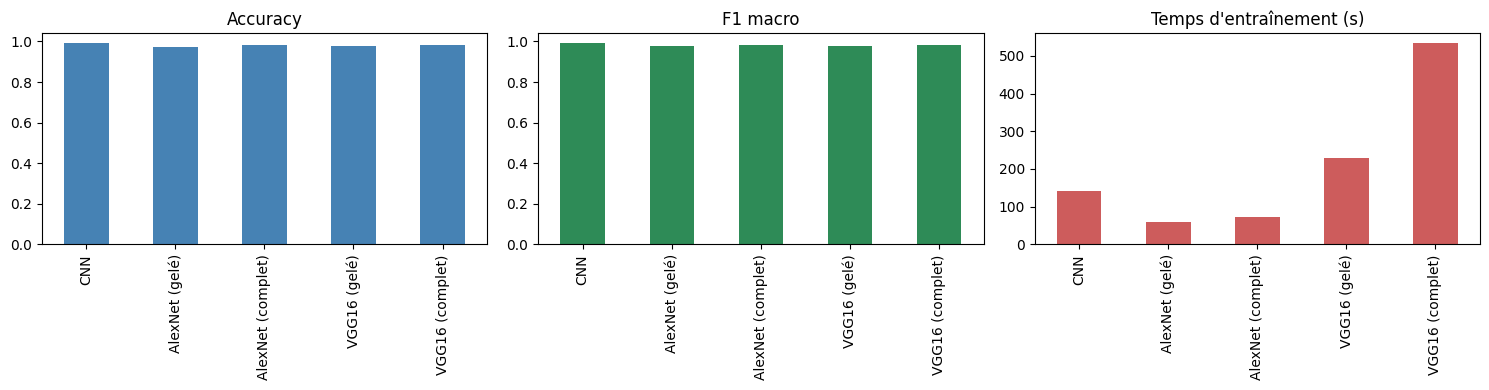

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["acc"].plot.bar(ax=axes[0], title="Accuracy", color="steelblue")
df["f1"].plot.bar(ax=axes[1], title="F1 macro", color="seagreen")
df["time"].plot.bar(ax=axes[2], title="Temps d'entraînement (s)", color="indianred")
plt.tight_layout(); plt.show()

Le CNN construit from scratch obtient les meilleurs résultats avec 99,29 % d’accuracy et 99,28 % de F1 macro, pour seulement 0,42 M de paramètres et 142 s d’entraînement. Les modèles pré-entraînés restent légèrement en dessous : AlexNet atteint 97,5 % (gelé) et 98,45 % (complet), VGG16 atteint 97,7 % (gelé) et 98,5 % (complet). Le fine-tuning complet améliore nettement la précision par rapport au gel des couches (environ +0,8 à +1 point), car MNIST est très différent d’ImageNet et les filtres doivent s’adapter. En termes de coût, AlexNet est le plus rapide (60 à 72 s), tandis que VGG16 est le plus lourd (134 M de paramètres) et le plus lent, avec 534 s en fine-tuning complet. Les pertes sont à interpréter avec prudence, car elles ont été calculées sur des jeux d’entraînement de tailles différentes (60 000 images pour le CNN, 10 000 pour les autres).

Ce lab m’a permis de maîtriser le cycle complet d’un projet de vision avec PyTorch : préparation des données, construction du modèle, entraînement sur GPU et évaluation.

Le résultat le plus surprenant : mon petit CNN (0,42 M de paramètres) a dépassé AlexNet et VGG16, avec 99,29 % d’accuracy contre 98,5 % au mieux. MNIST étant un dataset simple, un modèle plus gros n’est pas forcément meilleur. J’ai aussi vu que le fine-tuning complet apporte environ +1 point par rapport au gel des couches, mais avec un coût en temps (534 s pour VGG16, contre 142 s pour le CNN).

J’ai retenu qu’il faut rester critique face aux chiffres, car les modèles n’ont pas été entraînés sur les mêmes données (60 000 images contre 10 000).

Conclusion : le transfer learning est puissant, mais il est surtout utile pour des données complexes ou peu nombreuses. Pour une tâche simple, un modèle léger est plus efficace et plus économe.